# Fase 2 — Entendimiento de los datos (CRISP-DM)
**Proyecto 13:** Clasificación de actividades humanas desde señales inerciales (UCI HAR).

Objetivo de la fase: describir y **verificar** los datos crudos (`Inertial Signals`) antes de prepararlos.
No se entrena ningún modelo ni se ajustan estadísticos de normalización aquí (eso es Fase 3).

Etiquetas usadas: **[DATO]** (dataset / README UCI), **[SUPUESTO]**, **[HIPÓTESIS]**.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from scipy import signal

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from data_io import load_or_cache, load_activity_labels, CHANNELS, FS_HZ, WINDOW_LEN

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9


## 1. Carga y verificación estructural

In [2]:
Xtr, ytr, str_ = load_or_cache("train")
Xte, yte, ste = load_or_cache("test")
LABELS = load_activity_labels()
NAMES = [LABELS[i] for i in sorted(LABELS)]
print("Train:", Xtr.shape, ytr.shape, str_.shape)
print("Test :", Xte.shape, yte.shape, ste.shape)
print("Etiquetas:", LABELS)

Train: (7352, 128, 9) (7352,) (7352,)
Test : (2947, 128, 9) (2947,) (2947,)
Etiquetas: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


In [3]:
checks = {
    "train_shape": list(Xtr.shape), "test_shape": list(Xte.shape),
    "nan_train": int(np.isnan(Xtr).sum()), "nan_test": int(np.isnan(Xte).sum()),
    "inf_train": int(np.isinf(Xtr).sum()), "inf_test": int(np.isinf(Xte).sum()),
    "labels_train": sorted(map(int, np.unique(ytr))), "labels_test": sorted(map(int, np.unique(yte))),
    "subjects_train": sorted(map(int, np.unique(str_))), "subjects_test": sorted(map(int, np.unique(ste))),
}
inter = set(checks["subjects_train"]) & set(checks["subjects_test"])
checks["subject_overlap_train_test"] = sorted(inter)
assert not inter, "¡Fuga! sujetos compartidos entre train y test"
assert Xtr.shape[1:] == (WINDOW_LEN, 9) and Xte.shape[1:] == (WINDOW_LEN, 9)
# Duplicados exactos de ventanas
def n_dup(X):
    v = X.reshape(len(X), -1)
    return len(v) - len(np.unique(v, axis=0))
checks["dup_windows_train"] = n_dup(Xtr); checks["dup_windows_test"] = n_dup(Xte)
n_tot = len(set(checks["subjects_train"]) | set(checks["subjects_test"]))
checks["n_subjects_total"] = n_tot
checks["frac_windows_train"] = round(len(Xtr) / (len(Xtr) + len(Xte)), 4)
checks["frac_subjects_train"] = round(len(checks["subjects_train"]) / n_tot, 4)
for k, v in checks.items(): print(f"{k:28s}: {v}")

train_shape                 : [7352, 128, 9]
test_shape                  : [2947, 128, 9]
nan_train                   : 0
nan_test                    : 0
inf_train                   : 0
inf_test                    : 0
labels_train                : [1, 2, 3, 4, 5, 6]
labels_test                 : [1, 2, 3, 4, 5, 6]
subjects_train              : [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
subjects_test               : [2, 4, 9, 10, 12, 13, 18, 20, 24]
subject_overlap_train_test  : []
dup_windows_train           : 0
dup_windows_test            : 0
n_subjects_total            : 30
frac_windows_train          : 0.7139
frac_subjects_train         : 0.7


## 2. Distribución de clases y sujetos

,train_n,test_n,train_%,test_%,ratio_max_min_train
WALKING,1226,496,16.68,16.83,1.427
WALKING_UPSTAIRS,1073,471,14.59,15.98,
WALKING_DOWNSTAIRS,986,420,13.41,14.25,
SITTING,1286,491,17.49,16.66,
STANDING,1374,532,18.69,18.05,
LAYING,1407,537,19.14,18.22,


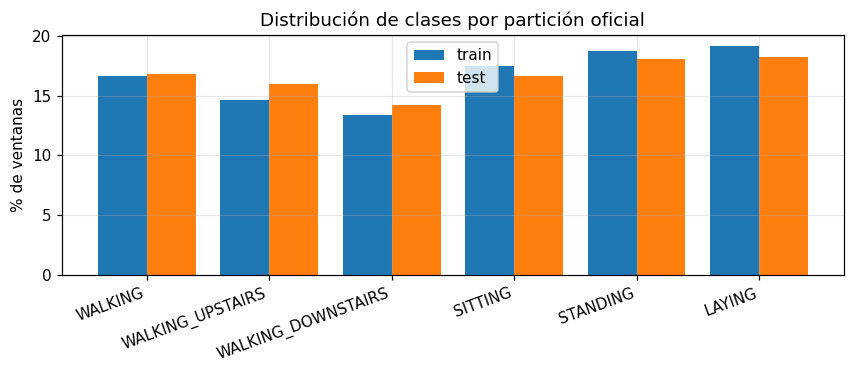

In [4]:
def dist(y):
    s = pd.Series(y).map(LABELS).value_counts().reindex(NAMES)
    return s
dc = pd.DataFrame({"train_n": dist(ytr), "test_n": dist(yte)})
dc["train_%"] = (100*dc.train_n/dc.train_n.sum()).round(2)
dc["test_%"] = (100*dc.test_n/dc.test_n.sum()).round(2)
dc["ratio_max_min_train"] = ""
dc.iloc[0, -1] = round(dc.train_n.max()/dc.train_n.min(), 3)
display(dc)
dc.to_csv(FIG/"tabla_distribucion_clases.csv")

fig, ax = plt.subplots(figsize=(8,3.5))
x = np.arange(6); w=.4
ax.bar(x-w/2, dc["train_%"], w, label="train"); ax.bar(x+w/2, dc["test_%"], w, label="test")
ax.set_xticks(x, NAMES, rotation=20, ha="right"); ax.set_ylabel("% de ventanas"); ax.legend()
ax.set_title("Distribución de clases por partición oficial")
fig.tight_layout(); fig.savefig(FIG/"fig01_distribucion_clases.png")

actividad,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING,total,split
sujeto,,,,,,,,
1,95,53,49,47,53,50,347,train
2,59,48,47,46,54,48,302,test
3,58,59,49,52,61,62,341,train
4,60,52,45,50,56,54,317,test
5,56,47,47,44,56,52,302,train
6,57,51,48,55,57,57,325,train
7,57,51,47,48,53,52,308,train
8,48,41,38,46,54,54,281,train
9,52,49,42,50,45,50,288,test


Ventanas por sujeto: min 281 max 409 media 343.3
¿Todo sujeto tiene las 6 actividades? True


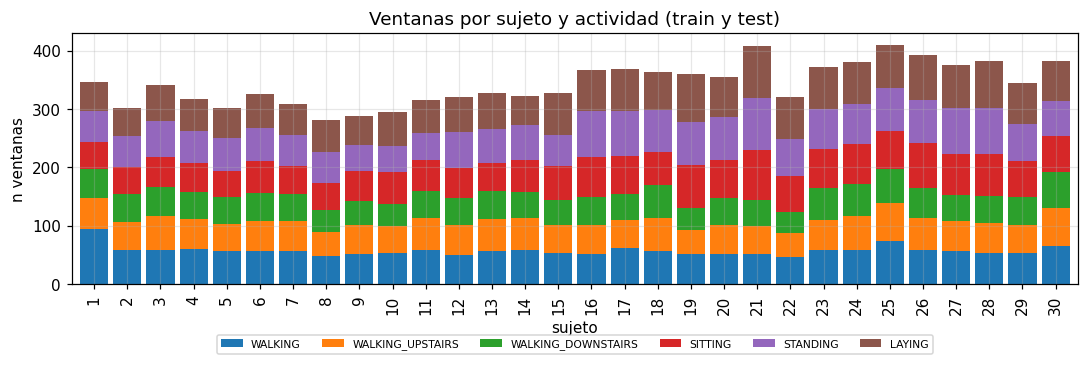

In [5]:
ct = pd.crosstab(pd.Series(np.r_[str_, ste], name="sujeto"),
                 pd.Series(np.r_[ytr, yte], name="actividad").map(LABELS)).reindex(columns=NAMES)
ct["total"] = ct.sum(1)
ct["split"] = ["train" if s in set(str_) else "test" for s in ct.index]
display(ct)
ct.to_csv(FIG/"tabla_sujeto_actividad.csv")
print("Ventanas por sujeto: min", ct.total.min(), "max", ct.total.max(), "media", round(ct.total.mean(),1))
print("¿Todo sujeto tiene las 6 actividades?", bool((ct[NAMES] > 0).all().all()))

fig, ax = plt.subplots(figsize=(10,3.5))
ct[NAMES].plot(kind="bar", stacked=True, ax=ax, width=.85)
ax.set_ylabel("n ventanas"); ax.set_title("Ventanas por sujeto y actividad (train y test)")
ax.legend(ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(.5,-.18))
fig.tight_layout(); fig.savefig(FIG/"fig02_ventanas_por_sujeto.png")

## 3. Verificación del preprocesamiento declarado por UCI
### 3.1 Solapamiento del 50 %
Si las ventanas son consecutivas con 50 % de solapamiento, la 2.ª mitad de la ventana *i* debe coincidir con la 1.ª mitad de la ventana *i+1* (mismo sujeto y actividad).

In [6]:
def overlap_check(X, y, s, tol=1e-6):
    same = (s[1:] == s[:-1]) & (y[1:] == y[:-1])
    d = np.abs(X[:-1, 64:, :] - X[1:, :64, :]).max(axis=(1, 2))
    return {"pares_consecutivos_mismo_sujeto_act": int(same.sum()),
            "con_solape_exacto": int((d[same] < tol).sum()),
            "pct": round(100 * (d[same] < tol).mean(), 2),
            "max_dif_en_pares_que_fallan": float(d[same][d[same] >= tol].max()) if (d[same] >= tol).any() else 0.0}
ov = {"train": overlap_check(Xtr, ytr, str_), "test": overlap_check(Xte, yte, ste)}
pd.DataFrame(ov).T

,pares_consecutivos_mismo_sujeto_act,con_solape_exacto,pct,max_dif_en_pares_que_fallan
train,7072.0,6752.0,95.48,4.873222
test,2827.0,2690.0,95.15,4.368351


### 3.2 Separación gravedad / cuerpo
UCI declara `body_acc = total_acc − gravedad`, con gravedad obtenida por Butterworth paso bajo a 0.3 Hz. Entonces `g = total − body` debería (a) tener módulo ≈ 1 g y (b) concentrar su energía bajo 0.3 Hz.

In [7]:
def grav(X): return X[..., 6:9] - X[..., 0:3]
G = grav(Xtr)
gmag = np.linalg.norm(G, axis=-1)
f, P = signal.welch(G - G.mean(1, keepdims=True), fs=FS_HZ, nperseg=128, axis=1)
frac_low_g = (P[:, f <= 0.5, :].sum(1) / P.sum(1)).mean()
fb, Pb = signal.welch(Xtr[..., 0:3], fs=FS_HZ, nperseg=128, axis=1)
frac_low_b = (Pb[:, fb <= 0.5, :].sum(1) / Pb.sum(1)).mean()
grav_res = {"|g| media": float(gmag.mean()), "|g| desv": float(gmag.std()),
            "|g| p1": float(np.percentile(gmag, 1)), "|g| p99": float(np.percentile(gmag, 99)),
            "frac_energia_<=0.5Hz_gravedad(sin DC)": float(frac_low_g),
            "frac_energia_<=0.5Hz_body_acc": float(frac_low_b),
            "media |body_acc| por ventana (promedio)": float(np.abs(Xtr[..., :3]).mean())}
for k,v in grav_res.items(): print(f"{k:42s}: {v:.4f}")
print("Nota: con ventanas de 128 muestras, la resolución de Welch es 50/128 ≈ 0.39 Hz.")

|g| media                                 : 1.0229
|g| desv                                  : 0.0132
|g| p1                                    : 0.9903
|g| p99                                   : 1.0478
frac_energia_<=0.5Hz_gravedad(sin DC)     : 0.7847
frac_energia_<=0.5Hz_body_acc             : 0.1859
media |body_acc| por ventana (promedio)   : 0.0780
Nota: con ventanas de 128 muestras, la resolución de Welch es 50/128 ≈ 0.39 Hz.


## 4. Estadísticos por canal (solo descriptivos; NO se usan para normalizar)

In [8]:
def chan_stats(X):
    v = X.reshape(-1, 9)
    return pd.DataFrame({"media": v.mean(0), "desv": v.std(0), "min": v.min(0),
                         "p1": np.percentile(v,1,0), "p99": np.percentile(v,99,0), "max": v.max(0)}, index=CHANNELS)
st_tr, st_te = chan_stats(Xtr), chan_stats(Xte)
display(st_tr.round(4)); display(st_te.round(4))
st_tr.to_csv(FIG/"tabla_stats_canal_train.csv"); st_te.to_csv(FIG/"tabla_stats_canal_test.csv")
print("Razón de escalas desv (máx/mín) en train:", round(st_tr.desv.max()/st_tr.desv.min(), 2))

,media,desv,min,p1,p99,max
body_acc_x,-0.0006,0.1948,-1.2322,-0.4748,0.7041,1.2999
body_acc_y,-0.0003,0.1224,-1.3453,-0.4298,0.3119,0.9760
body_acc_z,-0.0003,0.1068,-1.3647,-0.3517,0.3084,1.0669
body_gyro_x,0.0005,0.4067,-4.7337,-1.2527,1.1942,4.1555
body_gyro_y,-0.0008,0.3817,-5.9743,-1.1196,1.2608,5.7461
body_gyro_z,0.0001,0.2556,-2.7630,-0.8449,0.7118,2.3660
total_acc_x,0.8040,0.4141,-0.4666,-0.1661,1.6931,2.1976
total_acc_y,0.0288,0.3908,-1.5821,-0.6778,0.9760,1.2174
total_acc_z,0.0865,0.3577,-1.6396,-0.7523,0.9207,1.2814


,media,desv,min,p1,p99,max
body_acc_x,-0.0007,0.1843,-0.9054,-0.4266,0.6495,1.1576
body_acc_y,-0.0004,0.1206,-1.2510,-0.4252,0.3009,0.7757
body_acc_z,-0.0000,0.0955,-1.1068,-0.3264,0.2581,0.7101
body_gyro_x,-0.0132,0.3964,-3.4317,-1.2513,1.1104,3.2931
body_gyro_y,0.0015,0.3404,-3.1552,-1.0233,1.0804,3.4681
body_gyro_z,0.0028,0.2494,-2.6231,-0.7805,0.7153,1.8464
total_acc_x,0.8174,0.4065,-0.2777,-0.1665,1.6405,2.1127
total_acc_y,0.0043,0.4120,-1.5882,-0.9254,0.9900,1.1343
total_acc_z,0.0807,0.3079,-1.3475,-0.6621,0.9304,1.0434


Razón de escalas desv (máx/mín) en train: 3.88


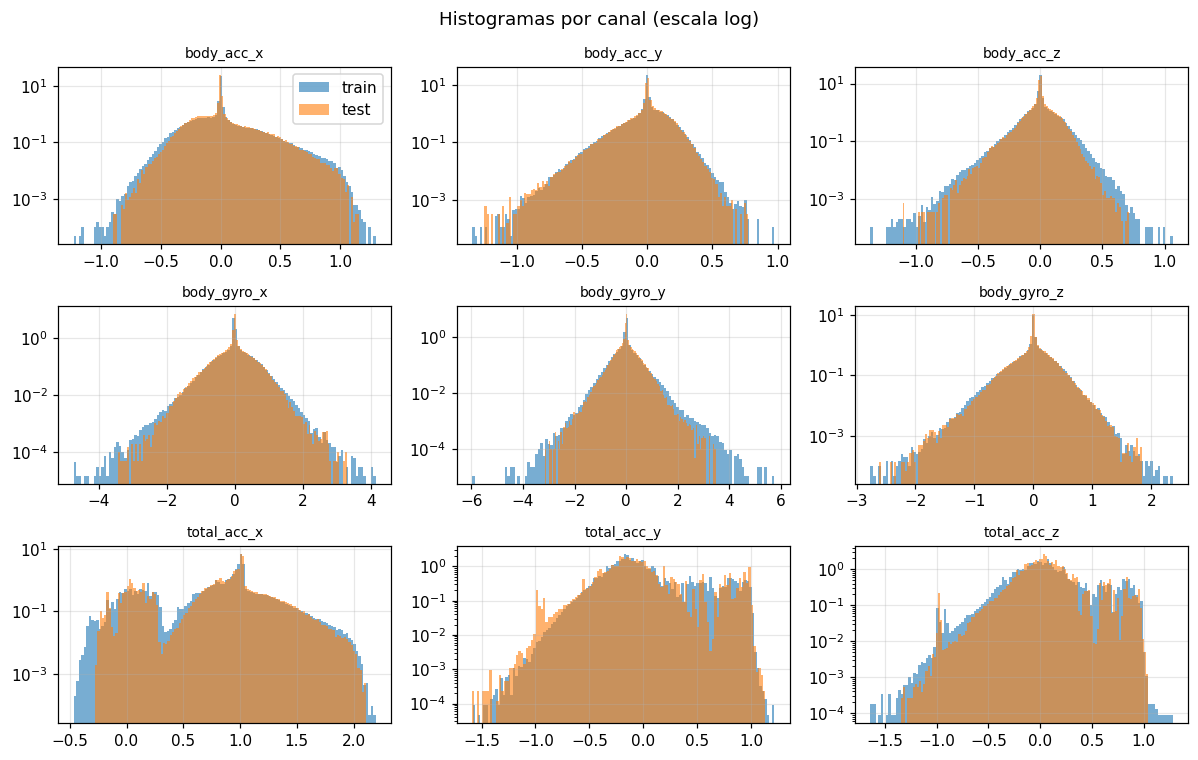

In [9]:
fig, axs = plt.subplots(3,3, figsize=(11,7), sharey=False)
for k, ax in enumerate(axs.ravel()):
    ax.hist(Xtr[..., k].ravel(), bins=120, density=True, alpha=.6, label="train")
    ax.hist(Xte[..., k].ravel(), bins=120, density=True, alpha=.6, label="test")
    ax.set_title(CHANNELS[k], fontsize=9); ax.set_yscale("log")
axs[0,0].legend(); fig.suptitle("Histogramas por canal (escala log)"); fig.tight_layout()
fig.savefig(FIG/"fig03_histogramas_canales.png")

## 5. Señales de ejemplo por actividad

Índices (train): {'WALKING': 448, 'WALKING_UPSTAIRS': 5832, 'WALKING_DOWNSTAIRS': 4866, 'SITTING': 3466, 'STANDING': 3259, 'LAYING': 6349}


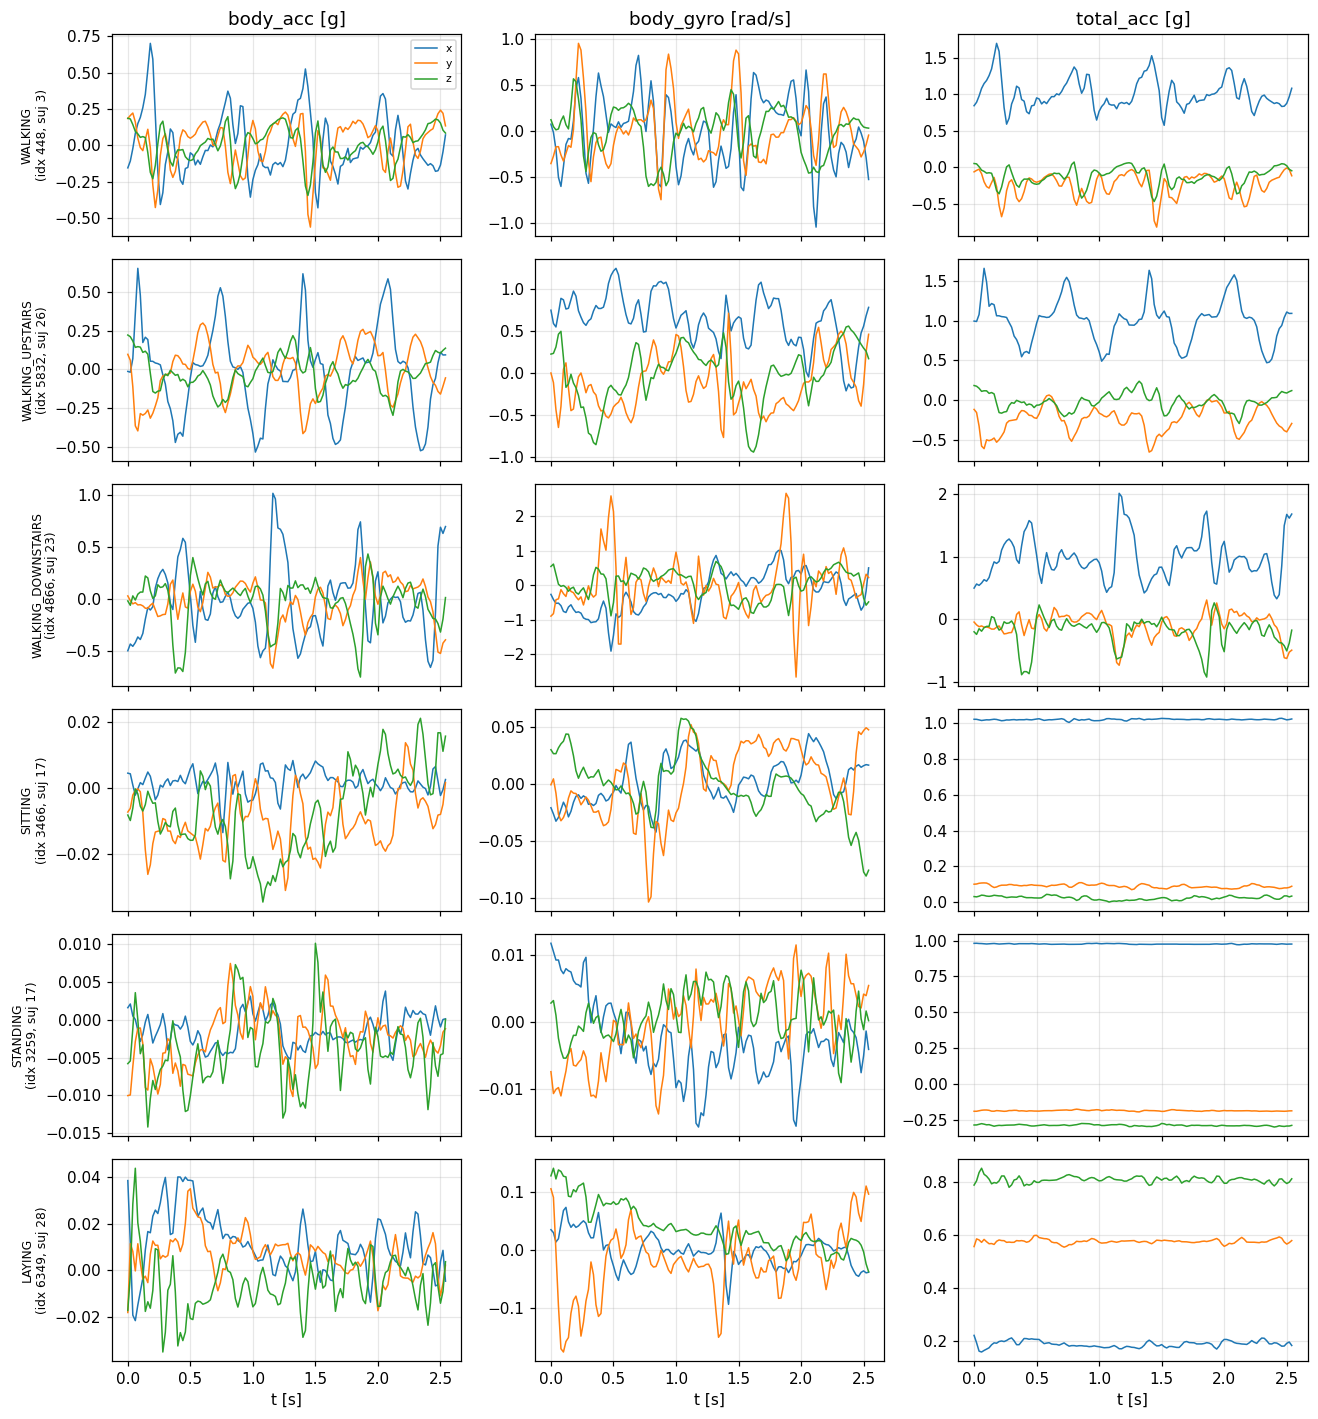

In [10]:
fig, axs = plt.subplots(6, 3, figsize=(12, 13), sharex=True)
t = np.arange(WINDOW_LEN) / FS_HZ
groups = [("body_acc [g]", 0), ("body_gyro [rad/s]", 3), ("total_acc [g]", 6)]
ex_idx = {}
for r, a in enumerate(sorted(LABELS)):
    i = int(rng.choice(np.where(ytr == a)[0])); ex_idx[LABELS[a]] = i
    for c, (nm, o) in enumerate(groups):
        for j, ax_lbl in enumerate("xyz"):
            axs[r, c].plot(t, Xtr[i, :, o+j], lw=1, label=ax_lbl)
        if r == 0: axs[r, c].set_title(nm)
    axs[r, 0].set_ylabel(f"{LABELS[a]}\n(idx {i}, suj {str_[i]})", fontsize=8)
axs[0,0].legend(fontsize=7); [axs[-1,c].set_xlabel("t [s]") for c in range(3)]
fig.tight_layout(); fig.savefig(FIG/"fig04_senales_ejemplo.png"); print("Índices (train):", ex_idx)

## 6. Firma espectral por actividad (módulo de body_acc)

Pico dominante [Hz]: {'WALKING': 1.5625, 'WALKING_UPSTAIRS': 1.5625, 'WALKING_DOWNSTAIRS': 3.515625, 'SITTING': 0.390625, 'STANDING': 0.390625, 'LAYING': 0.390625}


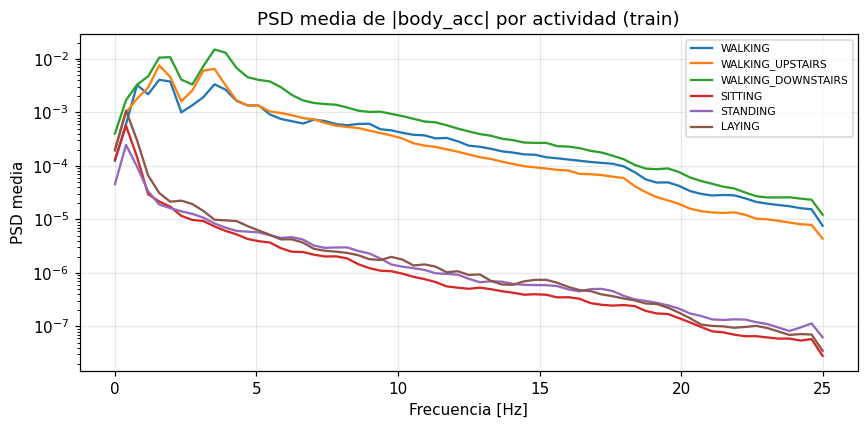

In [11]:
bmag = np.linalg.norm(Xtr[..., 0:3], axis=-1)
f, P = signal.welch(bmag - bmag.mean(1, keepdims=True), fs=FS_HZ, nperseg=128, axis=1)
fig, ax = plt.subplots(figsize=(8,4))
peak = {}
for a in sorted(LABELS):
    m = P[ytr == a].mean(0); ax.semilogy(f, m, label=LABELS[a]); peak[LABELS[a]] = float(f[m.argmax()])
ax.set_xlabel("Frecuencia [Hz]"); ax.set_ylabel("PSD media"); ax.legend(fontsize=7)
ax.set_title("PSD media de |body_acc| por actividad (train)")
fig.tight_layout(); fig.savefig(FIG/"fig05_psd_actividad.png"); print("Pico dominante [Hz]:", peak)

## 7. Separabilidad preliminar: energía y orientación
Indicadores simples por ventana: desviación estándar del módulo de `body_acc` (intensidad del movimiento) y media de cada eje de la gravedad estimada (orientación del teléfono).

std_|body_acc|             g_x             g_y          \
                             mean     std    mean     std    mean     std   
act                                                                         
WALKING                    0.1246  0.0257  0.9958  0.0283 -0.1812  0.0820   
WALKING_UPSTAIRS           0.1420  0.0265  0.9527  0.0494 -0.2685  0.0989   
WALKING_DOWNSTAIRS         0.2117  0.0368  0.9894  0.0264 -0.1488  0.0901   
SITTING                    0.0130  0.0246  0.9516  0.1033  0.1407  0.1864   
STANDING                   0.0112  0.0145  1.0011  0.0244 -0.1639  0.1006   
LAYING                     0.0156  0.0336  0.0734  0.1410  0.6502  0.3160   

                       g_z          
                      mean     std  
act                                 
WALKING            -0.0693  0.1589  
WALKING_UPSTAIRS   -0.1513  0.1977  
WALKING_DOWNSTAIRS -0.0568  0.1610  
SITTING             0.1538  0.2188  
STANDING           -0.0324  0.1587  
LAYING              0.5601  0.3890

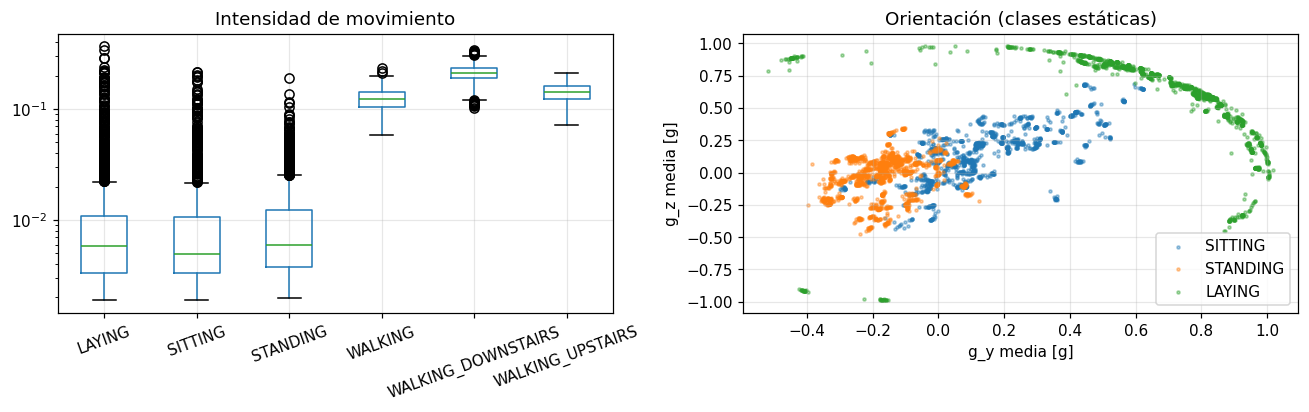

In [12]:
energy = bmag.std(1)
gmean = G.mean(1)
df7 = pd.DataFrame({"act": pd.Series(ytr).map(LABELS), "std_|body_acc|": energy,
                    "g_x": gmean[:,0], "g_y": gmean[:,1], "g_z": gmean[:,2]})
summ = df7.groupby("act").agg(["mean","std"]).reindex(NAMES).round(4); display(summ)
summ.to_csv(FIG/"tabla_energia_orientacion.csv")

fig, axs = plt.subplots(1,2, figsize=(12,4))
df7.boxplot(column="std_|body_acc|", by="act", ax=axs[0], rot=20); axs[0].set_yscale("log")
axs[0].set_title("Intensidad de movimiento"); axs[0].set_xlabel("")
for a in [4,5,6]:
    m = ytr == a; axs[1].scatter(gmean[m,1], gmean[m,2], s=4, alpha=.4, label=LABELS[a])
axs[1].set_xlabel("g_y media [g]"); axs[1].set_ylabel("g_z media [g]"); axs[1].legend()
axs[1].set_title("Orientación (clases estáticas)"); fig.suptitle(""); fig.tight_layout()
fig.savefig(FIG/"fig06_energia_orientacion.png")

In [13]:
# Solapamiento SITTING vs STANDING en orientación: exactitud de un umbral óptimo 1-D (solo descriptivo, en train)
def best_threshold_acc(a, b):
    v = np.r_[a, b]; lab = np.r_[np.zeros(len(a)), np.ones(len(b))]
    best = 0
    for th in np.quantile(v, np.linspace(0.01, .99, 199)):
        acc = max(((v > th) == lab).mean(), ((v <= th) == lab).mean()); best = max(best, acc)
    return round(float(best), 4)
sep = {}
for k, nm in enumerate(["g_x","g_y","g_z"]):
    sep[nm] = best_threshold_acc(gmean[ytr==4, k], gmean[ytr==5, k])
sep["std_|body_acc|"] = best_threshold_acc(energy[ytr==4], energy[ytr==5])
print("Exactitud de umbral único SITTING vs STANDING (train, optimista):", sep)

Exactitud de umbral único SITTING vs STANDING (train, optimista): {'g_x': 0.6432, 'g_y': 0.888, 'g_z': 0.756, 'std_|body_acc|': 0.5541}


## 8. Variabilidad entre sujetos (motivo de la partición por sujeto)

In [14]:
ds = pd.DataFrame({"suj": str_, "act": pd.Series(ytr).map(LABELS), "gx": gmean[:,0], "e": energy})
w = ds[ds.act=="WALKING"].groupby("suj").e.mean()
print("std|body_acc| en WALKING — media entre sujetos:", round(w.mean(),4), "| CV entre sujetos:", round(w.std()/w.mean(),3))
# ANOVA simple: fracción de varianza explicada por sujeto dentro de una actividad
def eta2(df, col):
    g = df.groupby("suj")[col]; tot = ((df[col]-df[col].mean())**2).sum()
    return float(((g.transform("mean")-df[col].mean())**2).sum()/tot)
eta = {a: {"eta2_energia": round(eta2(ds[ds.act==a],"e"),3), "eta2_g_x": round(eta2(ds[ds.act==a],"gx"),3)} for a in NAMES}
display(pd.DataFrame(eta).T)

std|body_acc| en WALKING — media entre sujetos: 0.1253 | CV entre sujetos: 0.178


,eta2_energia,eta2_g_x
WALKING,0.734,0.817
WALKING_UPSTAIRS,0.712,0.753
WALKING_DOWNSTAIRS,0.664,0.680
SITTING,0.034,0.352
STANDING,0.097,0.636
LAYING,0.171,0.657


## 9. Resumen exportado

In [15]:
res = {"checks": checks, "overlap": ov, "gravity": grav_res, "psd_peak_hz": peak,
       "sit_vs_stand_threshold_acc": sep, "eta2_subject": eta,
       "class_dist": dc.drop(columns="ratio_max_min_train").to_dict(),
       "windows_per_subject": {"min": int(ct.total.min()), "max": int(ct.total.max()), "mean": float(ct.total.mean())}}
Path("resumen_eda.json").write_text(json.dumps(res, indent=2, ensure_ascii=False, default=float))
print("Guardado resumen_eda.json")

Guardado resumen_eda.json
